# Лабораторная работа №2: Детекция и сегментация объектов

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Проверить разметку и распределения объектов.
- Дообучить компактный segmentation baseline.
- Сравнить аугментации и проанализировать ошибки.


## Теоретическая часть

В детекции модель предсказывает классы и bounding boxes, в сегментации — метку каждого пикселя. Для класса $c$ качество сегментации измеряет $IoU_c=|P_c\cap G_c|/|P_c\cup G_c|$. Для детекции mAP усредняет AP по классам и порогам IoU.

![Segmentation example](https://pytorch.org/vision/main/_images/sphx_glr_plot_visualization_utils_008.png)


### Математическая постановка

Составная функция потерь может иметь вид
$$\mathcal L=\mathcal L_{cls}+\lambda_{box}\mathcal L_{box}+\lambda_{mask}\mathcal L_{mask}.$$
Разбиение должно выполняться по исходным объектам/сериям, иначе соседние кадры дают утечку.


### Материалы

- [Torchvision segmentation models](https://pytorch.org/vision/stable/models.html#semantic-segmentation)
- [COCO metrics](https://cocodataset.org/#detection-eval)
- [Oxford-IIIT Pet Dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Проверить разметку и распределения объектов.
2. Дообучить компактный segmentation baseline.
3. Сравнить аугментации и проанализировать ошибки.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** LRASPP-MobileNetV3 или FCN-ResNet50, mixed precision.
- **Ограничение данных:** Oxford-IIIT Pet или до 2 000 изображений; в smoke-режиме — синтетический датасет.
- **Fallback:** замороженный backbone и 256 px.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    # локально работаю на Apple Silicon, поэтому кроме CUDA проверяю MPS
    DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})

{'device': 'mps', 'fast_dev_run': False, 'data_root': '/Users/filipp/Desktop/рабочий стол/Вуз/учеба/computer_vision/computer_vision_2026/data'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Маски Oxford-IIIT Pet

*Вес: 1 балл.*

**Постановка.** Сегментатор обучается на реальной пиксельной разметке.

Выполните следующие действия:
1. Загрузите trainval Oxford-IIIT Pet и совместно масштабируйте изображение и маску.
2. Убедитесь, что интерполяция маски сохраняет классы.

**Результат.** Датасет ds и преобразования img_tf, mask_tf.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [3]:
import hashlib
import torch.nn.functional as F
import torchvision
from torchvision import transforms as T
from torchvision.transforms import InterpolationMode
from PIL import Image

IMG_SIZE = 128 if FAST_DEV_RUN else 320
ds = torchvision.datasets.OxfordIIITPet(DATA_ROOT, split="trainval", target_types=("segmentation", "category"), download=True)

# изображение — билинейно, маска — только nearest, чтобы не появлялись промежуточные значения
img_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BILINEAR), T.PILToTensor()])
mask_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.NEAREST), T.PILToTensor()])

def load_pair(dataset, i):
    image, (mask, breed) = dataset[i]
    return img_tf(image.convert("RGB")), mask_tf(mask)[0], breed

x0, m0, _ = load_pair(ds, 0)
raw_values = set(np.unique(np.array(ds[0][1][0])).tolist())
check(set(torch.unique(m0).tolist()) <= {1, 2, 3}, f"после nearest-масштабирования маска содержит только исходные метки {sorted(raw_values)}")
check(tuple(x0.shape) == (3, IMG_SIZE, IMG_SIZE) and tuple(m0.shape) == (IMG_SIZE, IMG_SIZE), "изображение и маска приведены к одному размеру")
print("trainval:", len(ds), "| метки trimap:", sorted(raw_values), "(1 — животное, 2 — фон, 3 — граница)")

✔ после nearest-масштабирования маска содержит только исходные метки [1, 2, 3]
✔ изображение и маска приведены к одному размеру
trainval: 3680 | метки trimap: [1, 2, 3] (1 — животное, 2 — фон, 3 — граница)


### Разделение и кодирование меток

*Вес: 1 балл.*

**Постановка.** Оценка на validation требует непересекающихся индексов и корректных категориальных меток.

Выполните следующие действия:
1. Разделите trainval на train и validation.
2. Перекодируйте исходные метки 1–3 в 0–2 и соберите загрузчики.

**Результат.** train_ds, val_ds, loader, val_loader и normalize_mask.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [4]:
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

CLASS_NAMES = ["pet", "background", "border"]
def normalize_mask(m):
    """trimap 1/2/3 → 0/1/2 (pet, background, border)."""
    return (m.long() - 1).clamp_(0, 2)

class PetSeg(Dataset):
    """Кэширует уже масштабированные пары в памяти; flip=True — синхронное отражение пары."""
    def __init__(self, base, indices, flip=False):
        self.indices, self.flip = list(indices), flip
        pairs = [load_pair(base, i) for i in self.indices]
        self.images = torch.stack([p[0] for p in pairs])
        self.masks = torch.stack([normalize_mask(p[1]).to(torch.uint8) for p in pairs])
        self.breeds = [p[2] for p in pairs]
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, k):
        x, m = self.images[k], self.masks[k]
        if self.flip and torch.rand(1).item() < 0.5:
            x, m = x.flip(-1), m.flip(-1)
        return x, m

# одинаковые файлы (если есть) не должны попасть в разные выборки — проверяю md5 jpeg
file_hash = [hashlib.md5(Path(p).read_bytes()).hexdigest() for p in ds._images]
breeds = np.array(ds._labels)
all_idx = np.arange(len(ds))
if FAST_DEV_RUN:
    all_idx = np.random.RandomState(SEED).choice(all_idx, 240, replace=False)
train_idx, val_idx = train_test_split(all_idx, test_size=0.2, stratify=breeds[all_idx], random_state=SEED)
check(not ({file_hash[i] for i in train_idx} & {file_hash[i] for i in val_idx}), "train и validation не содержат одинаковых файлов")
check(len(set(train_idx) & set(val_idx)) == 0, "индексы train и validation не пересекаются")

train_ds = PetSeg(ds, train_idx)
import copy
train_aug_ds = copy.copy(train_ds); train_aug_ds.flip = True   # те же пары, только со случайным отражением
val_ds = PetSeg(ds, val_idx)
BATCH = 16
loader_gen = torch.Generator().manual_seed(SEED)
loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, generator=loader_gen)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False)
check(set(torch.unique(train_ds.masks).tolist()) <= {0, 1, 2}, "метки перекодированы в 0–2")
(ARTIFACTS / "split.json").write_text(json.dumps({"img_size": IMG_SIZE, "train_idx": [int(i) for i in train_idx],
                                                  "val_idx": [int(i) for i in val_idx]}))
print("train:", len(train_ds), "validation:", len(val_ds))

✔ train и validation не содержат одинаковых файлов
✔ индексы train и validation не пересекаются


✔ метки перекодированы в 0–2
train: 2944 validation: 736


### Проверка разметки
Перед обучением смотрю на случайные пары и на распределения: доли пикселей классов, площадь животного и долю «пустых» масок.

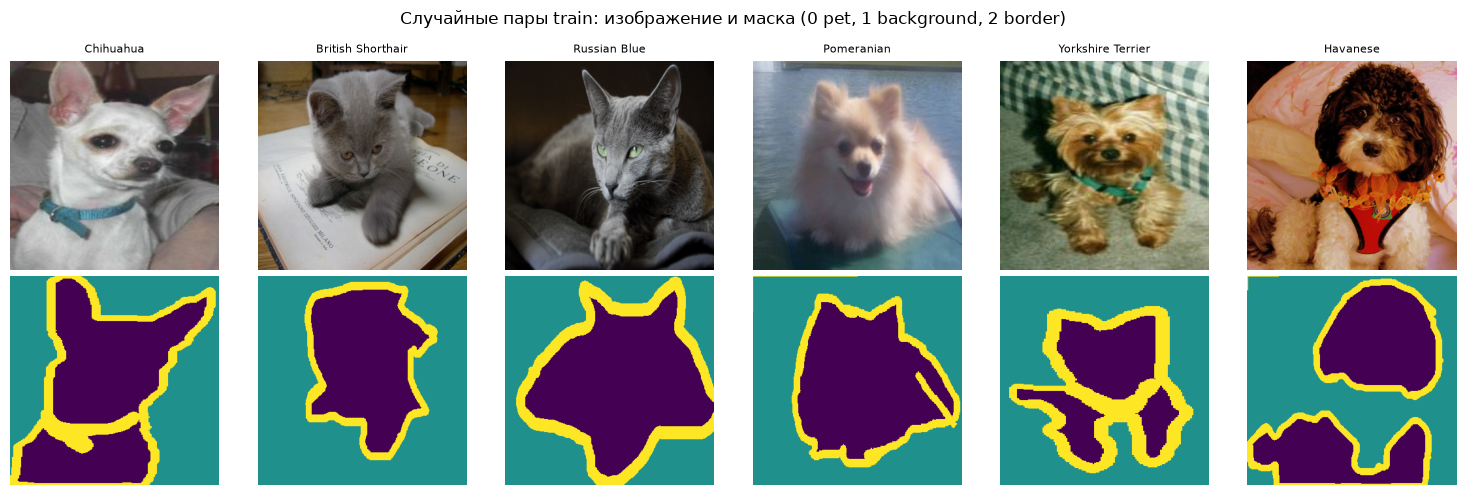

{
 "pixel_fraction": {
  "pet": 0.3010660685663638,
  "background": 0.5844919287640116,
  "border": 0.11444200266962466
 },
 "pet_area_quantiles": {
  "0.05": 0.08625732362270355,
  "0.25": 0.17698486149311066,
  "0.5": 0.27992677688598633,
  "0.75": 0.40104249119758606,
  "0.95": 0.5958730578422546
 },
 "empty_masks": 7,
 "n_breeds_train": 37
}


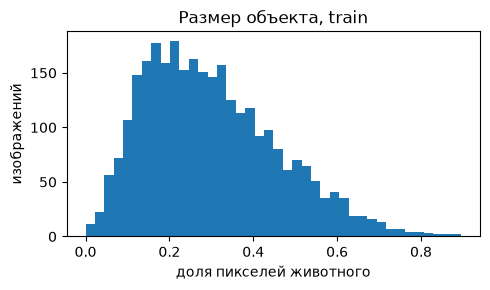

In [5]:
import matplotlib.pyplot as plt
rng = np.random.RandomState(SEED)
show = rng.choice(len(train_ds), 6, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for k, i in enumerate(show):
    axes[0, k].imshow(train_ds.images[i].permute(1, 2, 0)); axes[0, k].axis("off")
    axes[0, k].set_title(ds.classes[train_ds.breeds[i]], fontsize=8)
    axes[1, k].imshow(train_ds.masks[i], cmap="viridis", vmin=0, vmax=2); axes[1, k].axis("off")
fig.suptitle("Случайные пары train: изображение и маска (0 pet, 1 background, 2 border)")
fig.tight_layout(); fig.savefig(ARTIFACTS / "label_check.png", dpi=100); plt.show()

pix = torch.bincount(train_ds.masks.flatten().long(), minlength=3).double()
pet_area = (train_ds.masks == 0).float().mean((1, 2)).numpy()
label_stats = {"pixel_fraction": {c: float(v) for c, v in zip(CLASS_NAMES, pix / pix.sum())},
               "pet_area_quantiles": {q: float(np.quantile(pet_area, q)) for q in (0.05, 0.25, 0.5, 0.75, 0.95)},
               "empty_masks": int((pet_area == 0).sum()), "n_breeds_train": len(set(train_ds.breeds))}
(ARTIFACTS / "label_stats.json").write_text(json.dumps(label_stats, indent=2))
print(json.dumps(label_stats, indent=1))
plt.figure(figsize=(5, 3)); plt.hist(pet_area, bins=40); plt.xlabel("доля пикселей животного"); plt.ylabel("изображений")
plt.title("Размер объекта, train"); plt.tight_layout(); plt.show()

### Сегментатор и IoU

*Вес: 1 балл.*

**Постановка.** Пиксельная модель предсказывает логиты для каждого класса.

Выполните следующие действия:
1. Замените головы LRASPP на трёхклассовые.
2. Реализуйте IoU по пересечению и объединению масок.

**Результат.** Объект model и функция mean_iou.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
import torch.nn as nn
from torchvision.models.segmentation import lraspp_mobilenet_v3_large, LRASPP_MobileNet_V3_Large_Weights

def build_segmenter(num_classes=3):
    model = lraspp_mobilenet_v3_large(weights=LRASPP_MobileNet_V3_Large_Weights.COCO_WITH_VOC_LABELS_V1)
    # заменяю обе головы LRASPP (low- и high-level ветки) на трёхклассовые
    model.classifier.low_classifier = nn.Conv2d(model.classifier.low_classifier.in_channels, num_classes, 1)
    model.classifier.high_classifier = nn.Conv2d(model.classifier.high_classifier.in_channels, num_classes, 1)
    return model.to(DEVICE)

def confusion(pred, target, n=3):
    return torch.bincount(target.flatten().long() * n + pred.flatten().long(), minlength=n * n).reshape(n, n)

def iou_from_confusion(cm):
    cm = cm.double()
    inter = cm.diagonal()
    union = cm.sum(0) + cm.sum(1) - inter
    return torch.where(union > 0, inter / union.clamp(min=1), torch.full_like(inter, float("nan")))

def mean_iou(pred, target, n=3):
    """IoU каждого класса = |P∩G| / |P∪G| по пикселям; mIoU — среднее по классам, присутствующим в P∪G."""
    iou = iou_from_confusion(confusion(pred, target, n))
    return float(torch.nanmean(iou)), iou.tolist()

MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
def prepare(x):
    return (x.to(DEVICE).float() / 255 - MEAN) / STD

model = build_segmenter()
with torch.no_grad():
    out = model(prepare(train_ds.images[:2]))["out"]
check(tuple(out.shape) == (2, 3, IMG_SIZE, IMG_SIZE), f"логиты имеют форму {tuple(out.shape)}")
_t = torch.tensor([[0, 0], [1, 2]]); _p = torch.tensor([[0, 1], [1, 2]])
check(abs(mean_iou(_p, _t)[0] - (0.5 + 0.5 + 1.0) / 3) < 1e-6, "mean_iou на ручном примере совпадает с расчётом")

✔ логиты имеют форму (2, 3, 320, 320)
✔ mean_iou на ручном примере совпадает с расчётом


### Оптимизация сегментатора

*Вес: 1 балл.*

**Постановка.** Cross-entropy на масках задаёт обучающий сигнал каждому пикселю.

Выполните следующие действия:
1. Реализуйте шаг AdamW с обратным распространением.
2. Обучите модель установленное число эпох.

**Результат.** Функция train_one_epoch и массив history реальных значений loss.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


baseline эпоха 1/12: train loss 0.4773 (21 c)


baseline эпоха 2/12: train loss 0.2128 (41 c)


baseline эпоха 3/12: train loss 0.1758 (63 c)


baseline эпоха 4/12: train loss 0.1595 (85 c)


baseline эпоха 5/12: train loss 0.1438 (108 c)


...

baseline эпоха 8/12: train loss 0.1202 (175 c)


baseline эпоха 9/12: train loss 0.1156 (197 c)


baseline эпоха 10/12: train loss 0.1124 (220 c)


baseline эпоха 11/12: train loss 0.1105 (242 c)


baseline эпоха 12/12: train loss 0.1097 (264 c)
✔ loss конечен и уменьшился за обучение


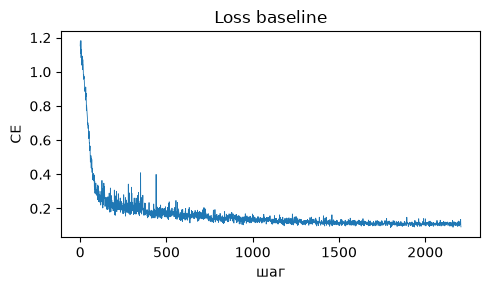

In [7]:
EPOCHS = 1 if FAST_DEV_RUN else 12
LR = 5e-4

def sync():
    if DEVICE == "mps": torch.mps.synchronize()
    elif DEVICE == "cuda": torch.cuda.synchronize()

def train_one_epoch(model, loader, optimizer, scheduler):
    model.train()
    losses = []
    for x, m in loader:
        logits = model(prepare(x))["out"]
        loss = F.cross_entropy(logits, m.to(DEVICE).long())
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step(); scheduler.step()
        losses.append(loss.item())
    return float(np.mean(losses)), losses

def train_segmenter(name, train_loader, epochs=EPOCHS):
    """Обучение с возобновлением по ckpt; возвращает модель и историю loss."""
    torch.manual_seed(SEED); loader_gen.manual_seed(SEED)
    model = build_segmenter()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, total_steps=epochs * len(train_loader), pct_start=0.1)
    ckpt = ARTIFACTS / f"ckpt_{name}.pt"
    state = {"epoch": 0, "history": [], "step_losses": [], "time_s": 0.0}
    if ckpt.exists():
        ck = torch.load(ckpt, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"])
        state = ck["state"]; print(f"{name}: продолжаю с эпохи {state['epoch']}")
    for epoch in range(state["epoch"], epochs):
        sync(); t0 = time.time()
        mean_loss, step_losses = train_one_epoch(model, train_loader, optimizer, scheduler)
        sync(); state["time_s"] += time.time() - t0
        state["history"].append(mean_loss); state["step_losses"] += step_losses; state["epoch"] = epoch + 1
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(), "state": state}, ckpt)
        print(f"{name} эпоха {epoch + 1}/{epochs}: train loss {mean_loss:.4f} ({state['time_s']:.0f} c)")
    return model, state

model, base_state = train_segmenter("baseline", loader)
history = base_state["history"]
check(all(np.isfinite(history)) and history[-1] < history[0], "loss конечен и уменьшился за обучение")
plt.figure(figsize=(5, 3)); plt.plot(base_state["step_losses"], lw=0.6); plt.xlabel("шаг"); plt.ylabel("CE"); plt.title("Loss baseline")
plt.tight_layout(); plt.show()

### Валидационный IoU

*Вес: 1 балл.*

**Постановка.** Матрица ошибок по пикселям позволяет вычислить классовый IoU.

Выполните следующие действия:
1. Накопите confusion matrix по validation.
2. Сохраните mIoU и checkpoint исходной модели.

**Результат.** segmentation.pt и val_metrics.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [8]:
@torch.no_grad()
def predict_masks(model, data_loader):
    model.eval()
    return torch.cat([model(prepare(x))["out"].argmax(1).to(torch.uint8).cpu() for x, _ in data_loader])

def evaluate_seg(model, data_loader, targets):
    pred = predict_masks(model, data_loader)
    cm = confusion(pred, targets)
    iou = iou_from_confusion(cm)
    return {"mIoU": float(torch.nanmean(iou)), "iou_per_class": dict(zip(CLASS_NAMES, iou.tolist())),
            "pixel_accuracy": float(cm.diagonal().sum() / cm.sum()), "confusion_matrix": cm.tolist()}, pred

base_val, base_val_pred = evaluate_seg(model, val_loader, val_ds.masks)
torch.save({"state_dict": model.state_dict(), "img_size": IMG_SIZE, "epochs": EPOCHS, "classes": CLASS_NAMES}, ARTIFACTS / "segmentation.pt")
(ARTIFACTS / "val_metrics.json").write_text(json.dumps({"model": "lraspp_mobilenet_v3_large", "n_val": len(val_ds),
    "epochs": EPOCHS, "train_time_s": base_state["time_s"], "loss_history": history, **base_val}, indent=2))
print(f"baseline validation mIoU = {base_val['mIoU']:.4f}", {k: round(v, 4) for k, v in base_val["iou_per_class"].items()})

baseline validation mIoU = 0.7986 {'pet': 0.8865, 'background': 0.9446, 'border': 0.5648}


### Совместное отражение и повторное обучение

*Вес: 1 балл.*

**Постановка.** Геометрическое преобразование изображения без идентичного преобразования маски портит разметку.

Выполните следующие действия:
1. Реализуйте синхронное горизонтальное отражение.
2. Обучите новый сегментатор при том же бюджете и сравните validation mIoU.

**Результат.** segmentation_aug.pt и augmentation_comparison.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [9]:
x_chk, m_chk = train_ds.images[0], train_ds.masks[0]
check(torch.equal(x_chk.flip(-1).flip(-1), x_chk) and torch.equal(m_chk.flip(-1)[:, 0], m_chk[:, -1]),
      "отражение применяется к изображению и маске синхронно (по ширине)")
aug_loader = DataLoader(train_aug_ds, batch_size=BATCH, shuffle=True, generator=loader_gen)
model_aug, aug_state = train_segmenter("flip", aug_loader)
aug_val, aug_val_pred = evaluate_seg(model_aug, val_loader, val_ds.masks)
torch.save({"state_dict": model_aug.state_dict(), "img_size": IMG_SIZE, "epochs": EPOCHS, "classes": CLASS_NAMES}, ARTIFACTS / "segmentation_aug.pt")
aug_cmp = {"budget": {"epochs": EPOCHS, "batch": BATCH, "lr": LR, "train_images": len(train_ds)},
           "baseline": {"val_mIoU": base_val["mIoU"], "train_time_s": base_state["time_s"]},
           "hflip": {"val_mIoU": aug_val["mIoU"], "train_time_s": aug_state["time_s"]},
           "delta_mIoU": aug_val["mIoU"] - base_val["mIoU"]}
(ARTIFACTS / "augmentation_comparison.json").write_text(json.dumps(aug_cmp, indent=2))
print(json.dumps(aug_cmp, indent=1))

✔ отражение применяется к изображению и маске синхронно (по ширине)


flip эпоха 1/12: train loss 0.4770 (23 c)


flip эпоха 2/12: train loss 0.2153 (45 c)


flip эпоха 3/12: train loss 0.1823 (68 c)


flip эпоха 4/12: train loss 0.1663 (90 c)


...

flip эпоха 9/12: train loss 0.1246 (203 c)


flip эпоха 10/12: train loss 0.1213 (226 c)


flip эпоха 11/12: train loss 0.1195 (248 c)


flip эпоха 12/12: train loss 0.1189 (271 c)


{
 "budget": {
  "epochs": 12,
  "batch": 16,
  "lr": 0.0005,
  "train_images": 2944
 },
 "baseline": {
  "val_mIoU": 0.7986308768406024,
  "train_time_s": 264.32297801971436
 },
 "hflip": {
  "val_mIoU": 0.8020649184046998,
  "train_time_s": 270.9812865257263
 },
 "delta_mIoU": 0.0034340415640974342
}


### Сегментация малых объектов

*Вес: 1 балл.*

**Постановка.** Размер категории, заданный по train, позволяет отдельно изучать слабые места модели.

Выполните следующие действия:
1. Определите порог площади объекта только на train.
2. Вычислите foreground IoU на малых объектах validation для обеих моделей.

**Результат.** small_objects.json с размером подвыборки и IoU двух моделей.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [10]:
def pet_area(masks):
    return (masks == 0).float().mean((1, 2))

SMALL_Q = 0.2
threshold = float(torch.quantile(pet_area(train_ds.masks), SMALL_Q))   # порог считается только по train
small = torch.where(pet_area(val_ds.masks) < threshold)[0]

def foreground_iou(pred, target):
    p, g = pred == 0, target == 0
    return float((p & g).sum() / (p | g).sum().clamp(min=1))

small_report = {"definition": f"доля пикселей животного < {SMALL_Q:.0%}-квантиля train", "threshold": threshold,
                "n_small_val": int(len(small)), "n_val": len(val_ds),
                "baseline_fg_iou_small": foreground_iou(base_val_pred[small], val_ds.masks[small]),
                "hflip_fg_iou_small": foreground_iou(aug_val_pred[small], val_ds.masks[small]),
                "baseline_fg_iou_all": foreground_iou(base_val_pred, val_ds.masks),
                "hflip_fg_iou_all": foreground_iou(aug_val_pred, val_ds.masks)}
(ARTIFACTS / "small_objects.json").write_text(json.dumps(small_report, indent=2, ensure_ascii=False))
print(json.dumps(small_report, indent=1, ensure_ascii=False))

{
 "definition": "доля пикселей животного < 20%-квантиля train",
 "threshold": 0.15822070837020874,
 "n_small_val": 150,
 "n_val": 736,
 "baseline_fg_iou_small": 0.8005295991897583,
 "hflip_fg_iou_small": 0.8056278228759766,
 "baseline_fg_iou_all": 0.8865069150924683,
 "hflip_fg_iou_all": 0.8890488743782043
}


### Отложенная оценка двух моделей

*Вес: 1 балл.*

**Постановка.** Test не должен влиять на обучение и выбор конфигурации.

Выполните следующие действия:
1. Загрузите test-раздел Oxford-IIIT Pet.
2. Оцените оба сохранённых сегментатора на одинаковых test-изображениях.

**Результат.** test_metrics.json с IoU на реальном test.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [11]:
test_base = torchvision.datasets.OxfordIIITPet(DATA_ROOT, split="test", target_types=("segmentation", "category"), download=True)
test_idx = np.arange(len(test_base))
if FAST_DEV_RUN:
    test_idx = test_idx[:64]
test_ds = PetSeg(test_base, test_idx)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)
test_report = {}
for name, m in [("baseline", model), ("hflip", model_aug)]:
    metrics, _ = evaluate_seg(m, test_loader, test_ds.masks)
    test_report[name] = metrics
test_report["n_test"] = len(test_ds)
(ARTIFACTS / "test_metrics.json").write_text(json.dumps(test_report, indent=2))
for name in ("baseline", "hflip"):
    print(f"{name}: test mIoU={test_report[name]['mIoU']:.4f}",
          {k: round(v, 4) for k, v in test_report[name]["iou_per_class"].items()})

baseline: test mIoU=0.8016 {'pet': 0.883, 'background': 0.9391, 'border': 0.5827}
hflip: test mIoU=0.8041 {'pet': 0.8846, 'background': 0.9402, 'border': 0.5876}


### Локализация ошибок маски

*Вес: 1 балл.*

**Постановка.** False positive и false negative выделяют различные режимы сбоя сегментатора.

Выполните следующие действия:
1. Посчитайте IoU, FP и FN для каждого изображения validation.
2. Сохраните наиболее сложные изображения и их индексы.

**Результат.** error_analysis.json с фактическими ошибками модели.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


 dataset_index                      breed  pet_iou  fp_pixels  fn_pixels  pet_area
          2248                      Boxer 0.285264       6961       2109  0.055947
           441                      Boxer 0.445076       7861       3359  0.120684
           589               Egyptian Mau 0.463600      10154        515  0.095078
          3578 Staffordshire Bull Terrier 0.506586        680        219  0.011152
          2354                  Chihuahua 0.516535      15764       1048  0.185645
          2247                      Boxer 0.528194      14649       1148  0.183916
             1                 Abyssinian 0.549012       8443        409  0.109229
          3304                    Samoyed 0.576711      16090       1035  0.237959
          1568                  Shiba Inu 0.584609        465        485  0.017793
          1255                        Pug 0.586607      10612       1099  0.173018


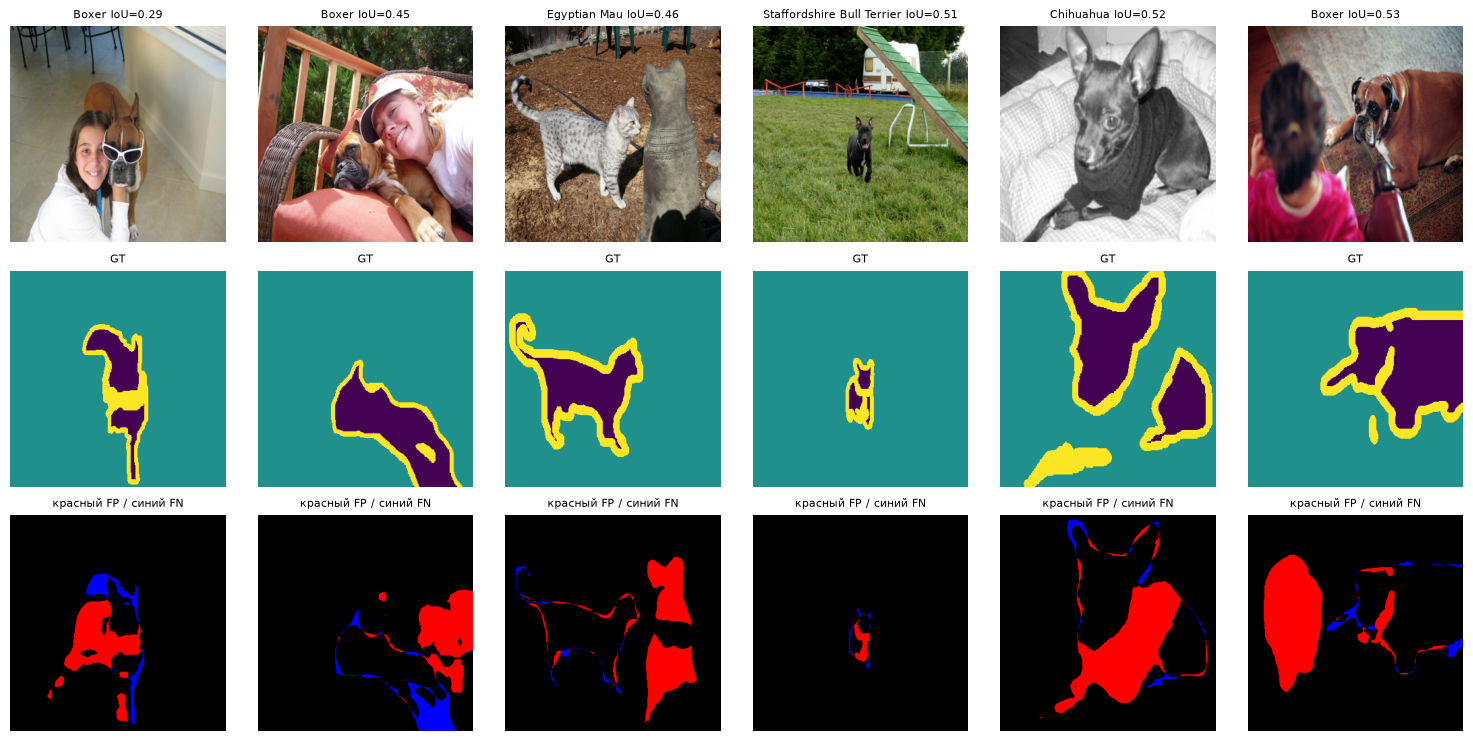

In [12]:
rows = []
for k in range(len(val_ds)):
    p, g = base_val_pred[k], val_ds.masks[k]
    rows.append({"val_position": k, "dataset_index": int(val_ds.indices[k]), "breed": ds.classes[val_ds.breeds[k]],
                 "pet_iou": foreground_iou(p, g), "mIoU": mean_iou(p, g)[0],
                 "fp_pixels": int(((p == 0) & (g != 0)).sum()), "fn_pixels": int(((p != 0) & (g == 0)).sum()),
                 "pet_area": float((g == 0).float().mean())})
rows.sort(key=lambda r: r["pet_iou"])
err = {"model": "baseline", "n_val": len(rows), "mean_pet_iou": float(np.mean([r["pet_iou"] for r in rows])),
       "share_fp_dominant_in_worst20": float(np.mean([r["fp_pixels"] > r["fn_pixels"] for r in rows[:20]])),
       "hardest": rows[:20]}
(ARTIFACTS / "error_analysis.json").write_text(json.dumps(err, indent=1, ensure_ascii=False))
import pandas as pd
print(pd.DataFrame(rows[:10])[["dataset_index", "breed", "pet_iou", "fp_pixels", "fn_pixels", "pet_area"]].to_string(index=False))

fig, axes = plt.subplots(3, 6, figsize=(15, 7.5))
for k, r in enumerate(rows[:6]):
    pos = r["val_position"]
    axes[0, k].imshow(val_ds.images[pos].permute(1, 2, 0)); axes[0, k].set_title(f"{r['breed']} IoU={r['pet_iou']:.2f}", fontsize=8)
    axes[1, k].imshow(val_ds.masks[pos], vmin=0, vmax=2); axes[1, k].set_title("GT", fontsize=8)
    p = base_val_pred[pos].numpy(); g = val_ds.masks[pos].numpy()
    err_map = np.zeros((*g.shape, 3)); err_map[(p == 0) & (g != 0)] = [1, 0, 0]; err_map[(p != 0) & (g == 0)] = [0, 0, 1]
    axes[2, k].imshow(err_map); axes[2, k].set_title("красный FP / синий FN", fontsize=8)
for ax in axes.flat: ax.axis("off")
fig.tight_layout(); fig.savefig(ARTIFACTS / "error_examples.png", dpi=100); plt.show()

### Поклассовая динамика аугментации

*Вес: 1 балл.*

**Постановка.** Средний IoU не показывает, каким классам помогло отражение.

Выполните следующие действия:
1. Сопоставьте поклассовый validation IoU исходной и дополненной моделей.
2. Сохраните изменения по каждому классу, не используя test для выбора модели.

**Результат.** class_deltas.json с наблюдаемыми изменениями IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [13]:
deltas = {c: {"baseline": base_val["iou_per_class"][c], "hflip": aug_val["iou_per_class"][c],
              "delta": aug_val["iou_per_class"][c] - base_val["iou_per_class"][c]} for c in CLASS_NAMES}
(ARTIFACTS / "class_deltas.json").write_text(json.dumps({"split": "validation", "classes": deltas}, indent=2))
print(pd.DataFrame(deltas).T.round(4))

            baseline   hflip   delta
pet           0.8865  0.8890  0.0025
background    0.9446  0.9462  0.0016
border        0.5648  0.5710  0.0061


### Творческий бонус: диагностические маски

*Вес: 1 дополнительный балл.*

**Постановка.** Ошибки на границах полезно изучать в пространстве изображения.

Выполните следующие действия:
1. Найдите сложнейшее validation-изображение по IoU.
2. Сохраните реальную RGB-картинку, истинную и предсказанную маски для визуального разбора.

**Результат.** bonus_hard_case.png и bonus_hard_case.json с индексом и IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


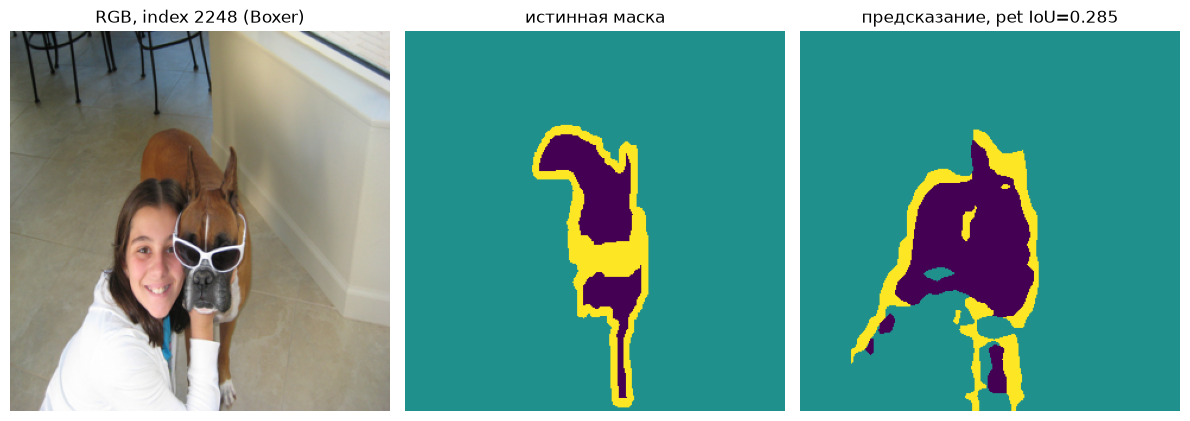

сложнейшее изображение validation: {'dataset_index': 2248, 'breed': 'Boxer', 'pet_iou': 0.2852639853954315, 'fp_pixels': 6961, 'fn_pixels': 2109}


In [14]:
hard = rows[0]
pos = hard["val_position"]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
axes[0].imshow(val_ds.images[pos].permute(1, 2, 0)); axes[0].set_title(f"RGB, index {hard['dataset_index']} ({hard['breed']})")
axes[1].imshow(val_ds.masks[pos], vmin=0, vmax=2); axes[1].set_title("истинная маска")
axes[2].imshow(base_val_pred[pos], vmin=0, vmax=2); axes[2].set_title(f"предсказание, pet IoU={hard['pet_iou']:.3f}")
for ax in axes: ax.axis("off")
fig.tight_layout(); fig.savefig(ARTIFACTS / "bonus_hard_case.png", dpi=110); plt.show()
(ARTIFACTS / "bonus_hard_case.json").write_text(json.dumps({"dataset_index": hard["dataset_index"], "val_position": pos,
    "breed": hard["breed"], "pet_iou": hard["pet_iou"], "mIoU": hard["mIoU"],
    "fp_pixels": hard["fp_pixels"], "fn_pixels": hard["fn_pixels"]}, indent=2, ensure_ascii=False))
print("сложнейшее изображение validation:", {k: hard[k] for k in ("dataset_index", "breed", "pet_iou", "fp_pixels", "fn_pixels")})

## Анализ результатов

**Задача и данные.** Семантическая сегментация Oxford-IIIT Pet на 3 класса trimap (pet / background / border). trainval (3 680) стратифицированно по породам разделён на train 2 944 и validation 736, test — официальный (3 669). Изображение и маска масштабируются к 320×320 совместно; маска — только nearest, после масштабирования в ней остаются исходные метки {1, 2, 3}. В train животное занимает в среднем 30 % пикселей, граница — 11 %, пустых масок 7.

**Модель и бюджет.** LRASPP-MobileNetV3-Large (веса COCO-VOC, обе головы заменены на 3-классовые), AdamW + OneCycle (max lr 5e-4), 12 эпох, batch 16, одинаковый порядок батчей для обеих моделей. Обучение — около 4,5 минут на модель на M3 Max (MPS, FP32: autocast на MPS ускорения не даёт).

| модель | val mIoU | val IoU pet / bg / border | test mIoU | test IoU pet / bg / border |
|---|---:|---|---:|---|
| baseline | 0,7986 | 0,887 / 0,945 / 0,565 | 0,8016 | 0,883 / 0,939 / 0,583 |
| + синхронное отражение | **0,8021** | 0,889 / 0,946 / 0,571 | **0,8041** | 0,885 / 0,940 / 0,588 |

Отражение дало +0,34 п. п. val mIoU и +0,25 п. п. test mIoU. Сильнее всего вырос самый трудный класс border (+0,6 п. п.). Выбор модели делался только по validation, test считался один раз для обеих моделей.

**Малые объекты** (доля пикселей животного меньше 20-го перцентиля train = 15,8 %; таких 150 из 736 изображений validation): foreground IoU 0,801 у baseline и 0,806 с отражением против 0,887/0,889 на всей validation. На малых объектах модель теряет около 9 п. п., аугментация помогает им примерно так же, как остальным (+0,5 п. п.).

**Ошибки** (`error_examples.png`, `error_analysis.json`). У 20 худших изображений по pet IoU в 75 % случаев FP-пикселей больше, чем FN:
1. люди рядом с собакой размечаются как животное: Boxer с девушкой (IoU 0,29), Boxer с ребёнком (0,53), Boxer с женщиной (0,45);
2. статуя кошки рядом с живой Egyptian Mau почти целиком попадает в pet (0,46) — модель реагирует на форму, а не на «живость» объекта;
3. маленький Staffordshire Bull Terrier на лужайке (1,1 % кадра) сегментирован частично;
4. у Chihuahua в свитере trimap отмечает голову, а тело в одежде нет, и модель «ошибается» там, где спорна сама разметка;
5. граница (border) — самый слабый класс (IoU ≈ 0,57): это полоса в несколько пикселей вокруг контура, и при 320 px любая неточность контура даёт ошибку.

**Ограничения:** одно разбиение и один seed; разница 0,3 п. п. мала и для уверенного вывода требует повторов с разными seed; FAST_DEV_RUN (240 изображений, 1 эпоха, 128 px) использовался только как smoke-проверка.

## Выводы

1. Компактная LRASPP-MobileNetV3 после 12 эпох даёт mIoU 0,80 на test и IoU животного 0,88.
2. Синхронное горизонтальное отражение даёт небольшой, но согласованный прирост на validation и test (+0,3 п. п.), прежде всего на классе границы.
3. Главный источник ошибок — FP на людях и животноподобных объектах рядом с питомцем, затем малые объекты (−9 п. п. IoU) и неоднозначная разметка trimap.